# 02 - Analyse Dense

Ce notebook présente le fine-tuning dense, métriques obtenues et limites méthodologiques du protocole subset 10%.


In [1]:
import sys
sys.path.insert(0, "..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Palette de couleurs
COLORS = ['#e30513', '#ffc103', '#0099ff', '#515151', '#f7a941', '#51a27e', '#702e78', '#7b003d']

# Style matplotlib
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('seaborn-whitegrid')

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

OUTPUT_DIR = Path("../results/analysis/02_dense_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 1. Chargement des artefacts utiles


In [2]:
TRAIN_DIR = Path("../results/dense/training/bge_base_biencoder_ft")
EVAL_DIR = Path("../results/dense/evaluation/dense_bge_base_ft_subset10_msmarco_dev")
BM25_DIR = Path("../results/baselines/bm25_msmarco_dev")

train_summary = json.loads((TRAIN_DIR / "train_summary.json").read_text())
train_config = json.loads((TRAIN_DIR / "config.json").read_text())
eval_metrics = json.loads((EVAL_DIR / "metrics.json").read_text())
eval_config = json.loads((EVAL_DIR / "config.json").read_text())
bm25_metrics = json.loads((BM25_DIR / "metrics.json").read_text())

print("=== Entraînement dense ===")
print(json.dumps(train_summary, indent=2, ensure_ascii=False))
print()
print("=== Évaluation dense fine-tunée ===")
print(json.dumps(eval_metrics, indent=2, ensure_ascii=False))


## 2. Contexte expérimental


In [3]:
print("Modèle entraîné         :", train_summary["model"])
print("Nombre d'exemples train :", f"{train_summary['n_examples']:,}")
print("Époques                 :", train_summary["epochs"])
print("Batch size              :", train_summary["batch_size"])
print()
print("Protocole d'évaluation  : subset 10% du corpus")
print("Passages évalués        :", f"{eval_config['n_corpus']:,}")
print("Requêtes évaluées       :", f"{eval_config['n_queries']:,}")
print()
print("Attention : ce run n'est pas directement comparable aux résultats full dev de BM25/Mistral.")


Modèle entraîné         : BAAI/bge-base-en-v1.5
Nombre d'exemples train : 20,000
Époques                 : 1
Batch size              : 2

Protocole d'évaluation  : subset 10% du corpus
Passages évalués        : 884,182
Requêtes évaluées       : 6,980

Attention : ce run n'est pas directement comparable aux résultats full dev de BM25/Mistral.


## 3. Visualisation des métriques du run dense


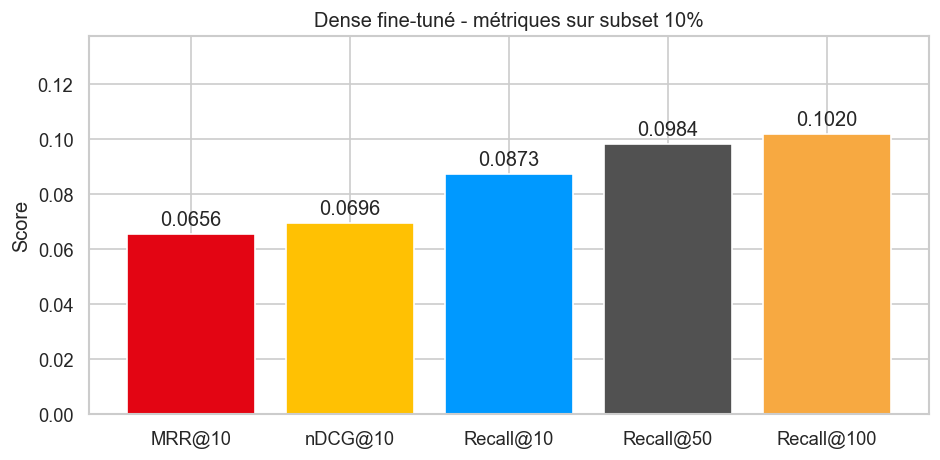

In [4]:
metric_order = ["MRR@10", "nDCG@10", "Recall@10", "Recall@50", "Recall@100"]
values = [eval_metrics[m] for m in metric_order]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(metric_order, values, color=[COLORS[i % len(COLORS)] for i in range(len(metric_order))], edgecolor="white")
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_ylim(0, max(values) * 1.25 + 0.01)
ax.set_ylabel("Score")
ax.set_title("Dense fine-tuné - métriques sur subset 10%")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dense_ft_metrics.png", dpi=150)
plt.show()


## 4. Mise en perspective avec BM25


In [5]:
comparison = {
    "BM25 full dev": {
        "MRR@10": bm25_metrics["MRR@10"],
        "nDCG@10": bm25_metrics["nDCG@10"],
    },
    "Dense FT subset10": {
        "MRR@10": eval_metrics["MRR@10"],
        "nDCG@10": eval_metrics["nDCG@10"],
    },
}

for name, vals in comparison.items():
    print(f"{name:<18} MRR@10={vals['MRR@10']:.4f}  nDCG@10={vals['nDCG@10']:.4f}")

print()
print("Cette comparaison est indicative seulement : BM25 est en full dev, alors que le dense fine-tuné est évalué sur subset 10%.")


BM25 full dev      MRR@10=0.1697  nDCG@10=0.2127
Dense FT subset10  MRR@10=0.0656  nDCG@10=0.0696

Cette comparaison est indicative seulement : BM25 est en full dev, alors que le dense fine-tuné est évalué sur subset 10%.
